---

# Conference Popularity and Association Pattern Mining pada Dataset DBLP

*Notebook 05: Task 5, Association Rule Mining.*

---

## Kelompok Tugas Besar Data Mining

- Izhar Alif Akbar (18223129)
- Harfhan Ikhtiar (18223123)
- Mahesa Andre (13523140)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Implementasi Association Rules**](#3)
4. [**Pembangkitan Rules (Task 5.1)**](#4)
5. [**Tabel Rules (Task 5.2)**](#5)
6. [**Asosiasi Paling Menarik (Task 5.3)**](#6)
7. [**Support dan Lift (Task 5.4)**](#7)
8. [**Interpretasi Support, Confidence, dan Lift (Task 5.5)**](#8)
9. [**Pola Publikasi Antarkonferensi (Task 5.6)**](#9)
10. [**Interpretasi dan Keterbatasan**](#10)
11. [**Ringkasan dan Langkah Berikutnya**](#11)

---

# Introduction <a name="1"></a>

---

## Overview

*Task 5 mengubah frequent itemsets dari Task 4 menjadi association rules, yaitu pernyataan berbentuk "author yang publish di konferensi X juga publish di konferensi Y". Notebook ini memakai frequent itemsets hasil FP-Growth dari notebook `04_fpgrowth`. Apriori pada notebook `03_apriori` menghasilkan itemset yang sama (diperiksa pada notebook `06_performance`), sehingga rules yang dihasilkan juga sama.*

## Aim

*Task 5.1 dan 5.2: membangkitkan association rules dengan min confidence 50%, lalu menampilkan support, confidence, dan lift setiap rule, termasuk 10 rule dengan lift tertinggi.*

*Task 5.3: mengidentifikasi hubungan antarkonferensi yang paling menarik.*

*Task 5.4: menganalisis apakah konferensi dengan support tinggi selalu menghasilkan lift tinggi.*

*Task 5.5: menjelaskan perbedaan interpretasi support, confidence, dan lift.*

*Task 5.6: menjelaskan pola publikasi antarkonferensi berdasarkan rules.*

## Metric

*Untuk rule $X \rightarrow Y$ dengan $N$ = jumlah seluruh author (1.821.757):*

$$\text{support}(X \rightarrow Y) = \frac{\text{count}(X \cup Y)}{N} \qquad
\text{confidence}(X \rightarrow Y) = \frac{\text{count}(X \cup Y)}{\text{count}(X)} \qquad
\text{lift}(X \rightarrow Y) = \frac{\text{confidence}(X \rightarrow Y)}{\text{support}(Y)}$$

*Support adalah proporsi seluruh author yang publish di semua konferensi pada X dan Y. Confidence adalah proporsi author X yang juga publish di Y. Lift membandingkan confidence dengan support Y: lift 1 berarti X tidak menambah peluang publish di Y, dan lift di atas 1 berarti author X lebih sering publish di Y dibanding author pada umumnya.*

*Rule disimpan jika confidence minimal 50%.*

## Approach

*Setiap frequent itemset berukuran dua atau lebih dipecah menjadi semua pasangan antecedent X dan consequent Y yang mungkin. Karena setiap subset dari frequent itemset juga frequent, count X dan Y selalu tersedia, sehingga ketiga metrik dihitung dari count bulat tanpa membaca ulang transaksi. Kode berada di `src/rules.py` dan diuji dengan `pytest` (contoh buku teks dan brute force yang menghitung langsung dari transaksi), lalu hasilnya dibandingkan dengan `mlxtend.frequent_patterns.association_rules`.*

*Rules dibangkitkan untuk keempat min support karena notebook `06_performance` membandingkan jumlah rules per min support. Analisis Task 5.2 sampai 5.6 memakai min support 0,1%, satu-satunya ambang yang menghasilkan pola kombinasi yang cukup kaya pada Task 4.*

---

# Initialization <a name="2"></a>

---

## Environment Setup

Notebook ini tidak memakai GPU. Prasyaratnya adalah notebook `04_fpgrowth` sudah dijalankan sehingga `outputs/fpgrowth/itemsets_<tag>.parquet` tersedia. Transaksi tidak dimuat ulang, sehingga notebook ini ringan.

Sel berikut memasang semua pustaka yang dipakai notebook ini.

In [1]:
%pip install -q --disable-pip-version-check numpy pandas scipy matplotlib pyarrow mlxtend

Note: you may need to restart the kernel to use updated packages.


## Import Libraries

Seluruh `import` untuk notebook ini dikumpulkan di satu sel. Modul proyek di `src/` diimpor setelah `Settings` menetapkan path-nya.

In [2]:
import inspect
import os
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from matplotlib.ticker import FuncFormatter
from scipy.stats import spearmanr

## Seed Everything

Pembangkitan rules bersifat deterministik. Seed tetap ditetapkan agar konsisten dengan notebook lain.

In [3]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)

seed_everything(42)

## Settings

Seluruh path, ambang, dan warna dipusatkan di kelas `Settings`. Palet warna sama dengan notebook sebelumnya.

In [4]:
class Settings:
    SEED = 42
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

    SRC_DIR = ROOT / "src"
    PROC_DIR = ROOT / "data" / "processed"
    TAB_DIR = ROOT / "outputs" / "tables"
    FIG_DIR = ROOT / "outputs" / "figures"
    ITEMSET_DIR = ROOT / "outputs" / "fpgrowth"
    RULE_DIR = ROOT / "outputs" / "rules"

    ITEMS = PROC_DIR / "tx_items.csv"
    TX_AUTHOR_INDEX = PROC_DIR / "tx_author_index.parquet"

    MIN_SUPPORTS = [0.001, 0.005, 0.01, 0.02]
    MAIN_SUPPORT = 0.001
    MIN_CONFIDENCE = 0.5
    TOP_K = 10

    INK = "#0b0b0b"
    INK_2 = "#52514e"
    MUTED = "#898781"
    GRID = "#e1e0d9"
    BASELINE = "#c3c2b7"
    SURFACE = "#fcfcfb"
    BLUE = "#2a78d6"
    BLUE_LIGHT = "#9ec5f4"
    ORANGE = "#eb6834"
    GRAY = "#b9b8b2"

CFG = Settings()
for d in (CFG.TAB_DIR, CFG.FIG_DIR, CFG.RULE_DIR):
    d.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(CFG.SRC_DIR))
import rules as rules_module
from fpgrowth import fpgrowth
from fpm_data import load_item_names
from rules import generate_rules, load_itemsets
from validation import compare_rules, mlxtend_rules_reference

Gaya grafik dan fungsi bantu diatur sekali di sini. Angka ditulis dengan pemisah ribuan titik dan desimal koma agar konsisten dengan notebook sebelumnya.

In [5]:
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": CFG.SURFACE, "axes.facecolor": CFG.SURFACE, "savefig.facecolor": CFG.SURFACE,
    "font.size": 9.5, "text.color": CFG.INK, "axes.labelcolor": CFG.INK_2,
    "xtick.color": CFG.INK_2, "ytick.color": CFG.INK_2, "axes.edgecolor": CFG.BASELINE,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": CFG.GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)


def fmt_id(value, digits=0):
    text = f"{value:,.{digits}f}"
    return text.replace(",", "X").replace(".", ",").replace("X", ".")


def pct_id(value, digits=1):
    return f"{value:.{digits}f}".replace(".", ",") + "%"


def save_fig(fig, name):
    fig.savefig(CFG.FIG_DIR / name)
    plt.show()


def save_table(df, name, index=True):
    df.to_csv(CFG.TAB_DIR / name, index=index)


def id_ticks(ax, axis="x"):
    formatter = FuncFormatter(lambda v, _: fmt_id(v, 0 if float(v).is_integer() else 1))
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(formatter)


def tag(ms):
    return f"{ms * 100:g}".replace(".", "p")


def is_tuple(col, value):
    return col.apply(lambda s: s == value)


COLS = ["rule", "support", "confidence", "lift", "count"]
FMT = {"support": "{:.3%}", "confidence": "{:.1%}", "lift": "{:.2f}"}

## Load Dataset

Frequent itemsets setiap min support dibaca dari keluaran notebook 04. Jumlah transaksi $N$ dibaca dari metadata tabel indeks author-based tanpa memuat isinya.

In [6]:
names = load_item_names(CFG.ITEMS)
N = pq.ParquetFile(CFG.TX_AUTHOR_INDEX).metadata.num_rows
itemsets = {ms: load_itemsets(CFG.ITEMSET_DIR / f"itemsets_{tag(ms)}.parquet") for ms in CFG.MIN_SUPPORTS}
print(f"N = {fmt_id(N)} author")
for ms, its in itemsets.items():
    print(f"min_sup {pct_id(ms * 100)}: {fmt_id(len(its))} frequent itemsets, "
          f"{fmt_id(sum(len(s) >= 2 for s in its))} berukuran dua atau lebih")

N = 1.821.757 author
min_sup 0,1%: 1.514 frequent itemsets, 940 berukuran dua atau lebih
min_sup 0,5%: 88 frequent itemsets, 22 berukuran dua atau lebih
min_sup 1,0%: 30 frequent itemsets, 1 berukuran dua atau lebih
min_sup 2,0%: 6 frequent itemsets, 0 berukuran dua atau lebih


---

# Implementasi Association Rules <a name="3"></a>

---

## 3.1 Kode

Seluruh isi `src/rules.py` ditampilkan di bawah.

In [7]:
print(inspect.getsource(rules_module))

"""Association rules dari frequent itemsets (support, confidence, lift)."""
from __future__ import annotations

from itertools import combinations
from pathlib import Path
from typing import Dict, FrozenSet, Mapping, Optional, Sequence, Union

import pandas as pd

COLUMNS = ["antecedent", "consequent", "n_antecedent", "n_consequent", "count",
           "antecedent_count", "consequent_count"]


def load_itemsets(path: Union[str, Path]) -> Dict[FrozenSet[int], int]:
    """Membaca frequent itemsets hasil notebook 04 (kolom `itemset` dan `count`)."""
    df = pd.read_parquet(path, columns=["itemset", "count"])
    return {frozenset(int(i) for i in s): int(c) for s, c in zip(df["itemset"], df["count"])}


def rule_label(antecedent: Sequence[int], consequent: Sequence[int], names: Mapping[int, str]) -> str:
    def side(items):
        return " + ".join(names[i] for i in items)

    return f"{side(antecedent)} → {side(consequent)}"


def generate_rules(itemsets: Mapping[FrozenSet[int], int

## 3.2 Contoh Kecil

Rules dibangkitkan dari contoh buku teks Han, Kamber, dan Pei (2012) yang sama dengan notebook 04 (sembilan transaksi, min support 2/9), dengan min confidence 70%. Itemset {I1, I2, I5} menghasilkan tiga rule dengan confidence 100%, sesuai buku teks.

In [8]:
toy = [frozenset(t) for t in ([1, 2, 5], [2, 4], [2, 3], [1, 2, 4], [1, 3], [2, 3], [1, 3], [1, 2, 3, 5], [1, 2, 3])]
toy_names = {i: f"I{i}" for i in range(1, 6)}
toy_rules = generate_rules(fpgrowth(toy, 2 / 9).itemsets, len(toy), 0.7, toy_names)
toy_rules[COLS].style.format(FMT)

,rule,support,confidence,lift,count
0,I5 → I1 + I2,22.222%,100.0%,2.25,2
1,I2 + I5 → I1,22.222%,100.0%,1.50,2
2,I5 → I1,22.222%,100.0%,1.50,2
3,I1 + I5 → I2,22.222%,100.0%,1.29,2
4,I4 → I2,22.222%,100.0%,1.29,2
5,I5 → I2,22.222%,100.0%,1.29,2


---

# Pembangkitan Rules (Task 5.1) <a name="4"></a>

---

## 4.1 Jumlah Rules per Min Support

Rules dibangkitkan dari frequent itemsets setiap min support dengan min confidence 50%. Kolom `k2` sampai `k6` menghitung rules menurut ukuran itemset asalnya; `k2` adalah rules satu-ke-satu seperti ICML → NeurIPS.

In [9]:
rules = {ms: generate_rules(its, N, CFG.MIN_CONFIDENCE, names) for ms, its in itemsets.items()}
for ms, df in rules.items():
    df.assign(antecedent=df["antecedent"].apply(list), consequent=df["consequent"].apply(list)) \
      .to_parquet(CFG.RULE_DIR / f"rules_{tag(ms)}.parquet", index=False)

def rule_counts(ms):
    df = rules[ms]
    size = df["n_antecedent"] + df["n_consequent"]
    row = {"min_support": ms, "itemset_ukuran_2plus": sum(len(s) >= 2 for s in itemsets[ms]),
           "kandidat_rule": sum(2 ** len(s) - 2 for s in itemsets[ms] if len(s) >= 2), "rules": len(df)}
    row.update({f"k{k}": int((size == k).sum()) for k in range(2, 7)})
    return row

counts = pd.DataFrame([rule_counts(ms) for ms in CFG.MIN_SUPPORTS])
save_table(counts, "t5_jumlah_rules.csv", index=False)
counts

,min_support,itemset_ukuran_2plus,kandidat_rule,rules,k2,k3,k4,k5,k6
0,0.001,940,6396,1387,22,436,555,313,61
1,0.005,22,48,7,4,3,0,0,0
2,0.010,1,2,1,1,0,0,0,0
3,0.020,0,0,0,0,0,0,0,0


> Pada min support 0,1%, 940 itemset berukuran dua atau lebih menghasilkan 6.396 kandidat rule, dan 1.387 di antaranya (21,7%) memiliki confidence minimal 50%. Hanya 22 rule berbentuk satu-ke-satu (`k2`); sebagian besar rule berasal dari itemset berukuran tiga sampai lima. Pada 0,5% tersisa 7 rule, pada 1% hanya satu rule (ICML → NeurIPS), dan pada 2% tidak ada rule karena tidak ada itemset berukuran dua.

## 4.2 Validasi dengan mlxtend

Rules setiap min support dibandingkan dengan `mlxtend.frequent_patterns.association_rules` pada itemset yang sama. Himpunan rules harus sama, dan support, confidence, serta lift harus sama sampai toleransi relatif $10^{-9}$.

In [10]:
checks = pd.DataFrame([
    {"min_support": ms, **compare_rules(rules[ms], mlxtend_rules_reference(itemsets[ms], N, CFG.MIN_CONFIDENCE))}
    for ms in CFG.MIN_SUPPORTS
])
save_table(checks, "t5_validasi_mlxtend.csv", index=False)
assert checks["identical"].all(), "rules berbeda dengan mlxtend"
checks

,min_support,n_ours,n_ref,missing,extra,metric_mismatch,identical
0,0.001,1387,1387,0,0,0,True
1,0.005,7,7,0,0,0,True
2,0.010,1,1,0,0,0,True
3,0.020,0,0,0,0,0,True


> Hasil keempat min support identik dengan mlxtend: tidak ada rule yang hilang, berlebih, atau berbeda nilai support, confidence, dan lift.

---

# Tabel Rules (Task 5.2) <a name="5"></a>

---

## 5.1 Sepuluh Rule dengan Lift Tertinggi

Tabel pertama mengikuti spesifikasi, yaitu sepuluh rule dengan lift tertinggi pada min support 0,1% dari seluruh rule. Tabel kedua membatasi pada rule satu-ke-satu (satu konferensi ke satu konferensi), yang paling mudah dibaca sebagai "author konferensi A juga publish di konferensi B".

In [11]:
main = rules[CFG.MAIN_SUPPORT]
one = main[(main["n_antecedent"] == 1) & (main["n_consequent"] == 1)].copy()
top10 = main.head(CFG.TOP_K)[COLS]
save_table(top10, "t5_top10_lift.csv", index=False)
save_table(one[COLS], "t5_rules_satu_ke_satu.csv", index=False)
print(f"Rules pada min support 0,1%: {fmt_id(len(main))}, di antaranya {len(one)} rule satu-ke-satu")
display(top10.style.format(FMT))
display(one.head(CFG.TOP_K)[COLS].style.format(FMT))

Rules pada min support 0,1%: 1.387, di antaranya 22 rule satu-ke-satu


,rule,support,confidence,lift,count
0,ECCV + ACM Multimedia + NeurIPS → AAAI + CVPR + ICCV,0.100%,61.2%,172.27,1827
1,CVPR + ECCV + ICML → ICCV + ICLR + NeurIPS,0.101%,50.2%,171.81,1849
2,CVPR + ICCV + ICML + NeurIPS → ECCV + ICLR,0.101%,51.4%,159.38,1849
3,CVPR + ECCV + ICML + NeurIPS → ICCV + ICLR,0.101%,59.1%,157.30,1849
4,ECCV + ICCV + ICML → CVPR + ICLR + NeurIPS,0.101%,61.4%,156.21,1849
5,ICLR + NAACL-HLT → ACL + EMNLP + NeurIPS,0.105%,50.4%,152.46,1917
6,CVPR + ICCV + ACM Multimedia + NeurIPS → AAAI + ECCV,0.100%,57.5%,147.66,1827
7,EMNLP + NAACL-HLT + NeurIPS → ACL + ICLR,0.105%,54.6%,146.26,1917
8,CVPR + ECCV + ACM Multimedia + NeurIPS → AAAI + ICCV,0.100%,68.5%,145.44,1827
9,CVPR + ECCV + ICML → ICCV + ICLR,0.108%,53.6%,142.63,1973


,rule,support,confidence,lift,count
153,ECOC → OFC,0.249%,66.5%,80.12,4530
185,ASRU → INTERSPEECH,0.108%,72.7%,74.17,1961
644,CoRL → ICRA,0.114%,58.1%,37.11,2084
653,EACL → ACL,0.161%,59.6%,36.59,2924
666,SPAWC → ICC,0.106%,53.0%,36.23,1926
734,Conference on Designing Interactive Systems → CHI,0.174%,55.8%,33.99,3167
740,SPAWC → GLOBECOM,0.100%,50.3%,33.80,1828
774,EACL → EMNLP,0.165%,61.2%,32.85,3004
803,NAACL-HLT → ACL,0.419%,52.3%,32.13,7629
844,IJCNLP-AACL → ACL,0.104%,50.5%,30.98,1886


> Sepuluh rule dengan lift tertinggi seluruhnya berupa rule panjang di sekitar machine learning, computer vision, dan NLP, dipimpin ECCV + ACM Multimedia + NeurIPS → AAAI + CVPR + ICCV dengan lift 172,27. Count kesepuluh rule itu hanya 1.827 sampai 1.973 author, sedikit di atas ambang 1.822, sehingga rule ini berlaku untuk kelompok author yang kecil dan sangat spesifik. Lift-nya tinggi terutama karena consequent-nya berisi dua atau tiga konferensi sekaligus (bagian 7).
>
> Di antara rule satu-ke-satu, lift tertinggi adalah ECOC → OFC (80,12) dan ASRU → INTERSPEECH (74,17), sedangkan rule dengan count terbesar adalah ICML → NeurIPS (18.503 author).

## 5.2 Rules pada Min Support Lain

Pada min support yang lebih tinggi, jumlah rules jauh lebih sedikit sehingga seluruhnya ditampilkan.

In [12]:
for ms in CFG.MIN_SUPPORTS[1:]:
    print(f"min_sup {pct_id(ms * 100)}: {len(rules[ms])} rules")
    if len(rules[ms]):
        display(rules[ms][COLS].style.format(FMT))

min_sup 0,5%: 7 rules


,rule,support,confidence,lift,count
0,ICLR + NeurIPS → ICML,0.572%,58.3%,33.32,10413
1,ICML + NeurIPS → ICLR,0.572%,56.3%,32.91,10413
2,ICLR + ICML → NeurIPS,0.572%,80.4%,25.35,10413
3,ECCV → CVPR,0.755%,58.3%,22.28,13752
4,ICCV → CVPR,0.848%,57.0%,21.80,15441
5,ICML → NeurIPS,1.016%,58.0%,18.28,18503
6,ICLR → NeurIPS,0.980%,57.3%,18.06,17852


min_sup 1,0%: 1 rules


,rule,support,confidence,lift,count
0,ICML → NeurIPS,1.016%,58.0%,18.28,18503


min_sup 2,0%: 0 rules


> Pada 0,5% hanya ada tujuh rule, seluruhnya di machine learning (ICML, ICLR, NeurIPS) dan computer vision (ECCV, ICCV, CVPR). Confidence tertinggi dimiliki ICLR + ICML → NeurIPS (80,4%): empat dari lima author yang publish di ICLR dan ICML juga publish di NeurIPS.

---

# Asosiasi Paling Menarik (Task 5.3) <a name="6"></a>

---

Rule satu-ke-satu dipakai untuk menilai hubungan antarkonferensi karena paling mudah dibaca. Sebuah hubungan dianggap menarik jika lift-nya tinggi, artinya author konferensi A jauh lebih sering publish di B dibanding author pada umumnya. Untuk setiap rule A → B ditampilkan juga confidence arah balik B → A (dihitung dari count yang sama) dan perbandingan ukuran kedua konferensi, sehingga terlihat apakah hubungannya timbal balik atau hanya satu arah.

Rule satu-ke-satu: 22 | pasangan yang berlaku dua arah: 0 | rule dari konferensi lebih kecil ke lebih besar: 22
Confidence arah balik: 4,1% sampai 32,4%


,rule,lift,confidence,confidence_balik,antecedent_count,consequent_count,rasio_ukuran
153,ECOC → OFC,80.12,66.5%,30.0%,6815,15115,2.2
185,ASRU → INTERSPEECH,74.17,72.7%,11.0%,2699,17845,6.6
644,CoRL → ICRA,37.11,58.1%,7.3%,3584,28542,8.0
653,EACL → ACL,36.59,59.6%,9.9%,4906,29677,6.0
666,SPAWC → ICC,36.23,53.0%,7.2%,3637,26626,7.3
734,Conference on Designing Interactive Systems → CHI,33.99,55.8%,10.6%,5676,29904,5.3
740,SPAWC → GLOBECOM,33.80,50.3%,6.7%,3637,27088,7.4
774,EACL → EMNLP,32.85,61.2%,8.8%,4906,33954,6.9
803,NAACL-HLT → ACL,32.13,52.3%,25.7%,14574,29677,2.0
844,IJCNLP-AACL → ACL,30.98,50.5%,6.4%,3737,29677,7.9


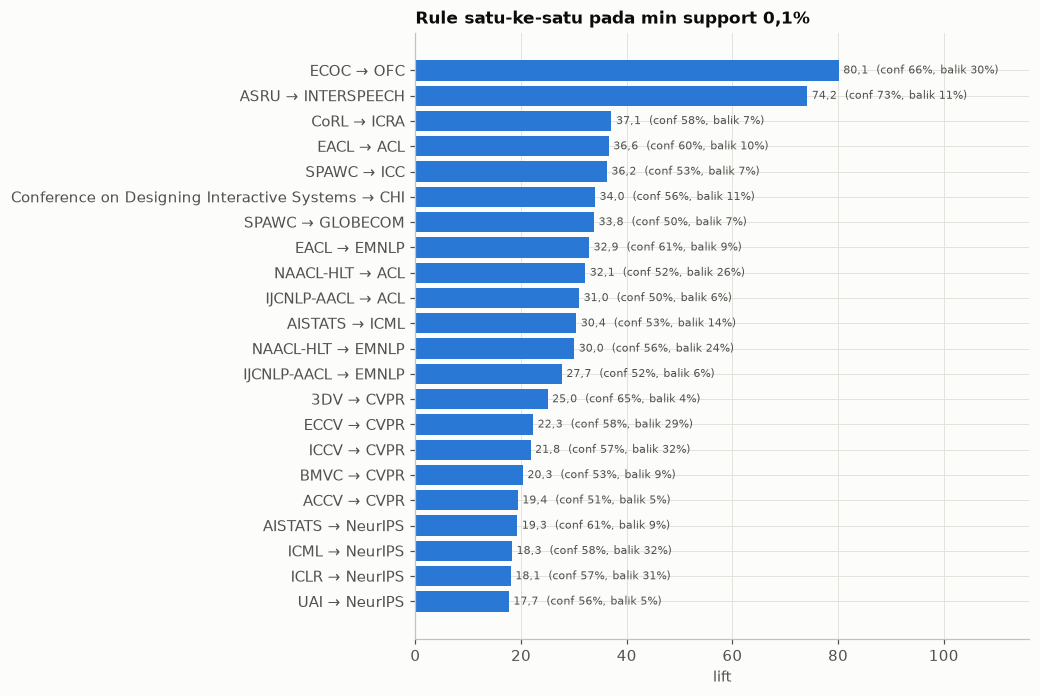

In [13]:
one["confidence_balik"] = one["count"] / one["consequent_count"]
one["rasio_ukuran"] = one["consequent_count"] / one["antecedent_count"]
pair_key = [frozenset(a + c) for a, c in zip(one["antecedent"], one["consequent"])]
two_way = int((pd.Series(pair_key).value_counts() == 2).sum())
small_to_big = int((one["antecedent_count"] < one["consequent_count"]).sum())
print(f"Rule satu-ke-satu: {len(one)} | pasangan yang berlaku dua arah: {two_way} | "
      f"rule dari konferensi lebih kecil ke lebih besar: {small_to_big}")
print(f"Confidence arah balik: {pct_id(one['confidence_balik'].min() * 100)} sampai {pct_id(one['confidence_balik'].max() * 100)}")
asym_cols = ["rule", "lift", "confidence", "confidence_balik", "antecedent_count", "consequent_count", "rasio_ukuran"]
save_table(one[asym_cols], "t5_rules_satu_ke_satu_arah.csv", index=False)
display(one[asym_cols].style.format({"lift": "{:.2f}", "confidence": "{:.1%}", "confidence_balik": "{:.1%}", "rasio_ukuran": "{:.1f}"}))

fig, ax = plt.subplots(figsize=(7.2, 0.28 * len(one) + 1.0))
plot = one.iloc[::-1]
ax.barh(plot["rule"], plot["lift"], color=CFG.BLUE)
for y, (lift, conf, back) in enumerate(zip(plot["lift"], plot["confidence"], plot["confidence_balik"])):
    ax.annotate(f"{fmt_id(lift, 1)}  (conf {pct_id(conf * 100, 0)}, balik {pct_id(back * 100, 0)})", (lift, y),
                xytext=(3, 0), textcoords="offset points", va="center", fontsize=7.5, color=CFG.INK_2)
ax.set_xlabel("lift")
ax.set_title("Rule satu-ke-satu pada min support 0,1%")
ax.set_xlim(0, plot["lift"].max() * 1.45)
save_fig(fig, "t5_rules_satu_ke_satu.png")

> Tidak ada pasangan konferensi yang berlaku dua arah. Seluruh 22 rule satu-ke-satu mengarah dari konferensi yang lebih kecil ke konferensi yang lebih besar dalam bidang yang sama, misalnya EACL → ACL, BMVC → CVPR, dan UAI → NeurIPS, dengan confidence arah balik hanya 4,1% sampai 32,4%. Artinya, mayoritas author konferensi yang lebih kecil juga publish di konferensi utama bidangnya, tetapi hanya sebagian kecil author konferensi utama yang publish di konferensi kecil itu.
>
> Ada dua jenis hubungan yang paling menarik. Pertama, hubungan dengan lift tertinggi: ECOC → OFC (lift 80,12; 66,5% author ECOC publish di OFC) dan ASRU → INTERSPEECH (lift 74,17; 72,7% author ASRU publish di INTERSPEECH). Keduanya pasangan konferensi di bidang yang sempit, yaitu komunikasi optik dan pengenalan suara, sehingga author-nya sangat terkonsentrasi. Kedua, hubungan yang paling mendekati timbal balik: ICCV → CVPR, ICML → NeurIPS, ICLR → NeurIPS, ECOC → OFC, dan ECCV → CVPR, dengan confidence arah balik 28,9% sampai 32,4%. Pasangan ini adalah konferensi utama yang ukurannya mirip (konferensi tujuan 1,8 sampai 2,2 kali lebih besar) dalam bidang yang sama.

---

# Support dan Lift (Task 5.4) <a name="7"></a>

---

## 7.1 Support Rule dan Lift

Setiap titik adalah satu rule pada min support 0,1%. Warna membedakan consequent satu konferensi dan consequent dua konferensi atau lebih.

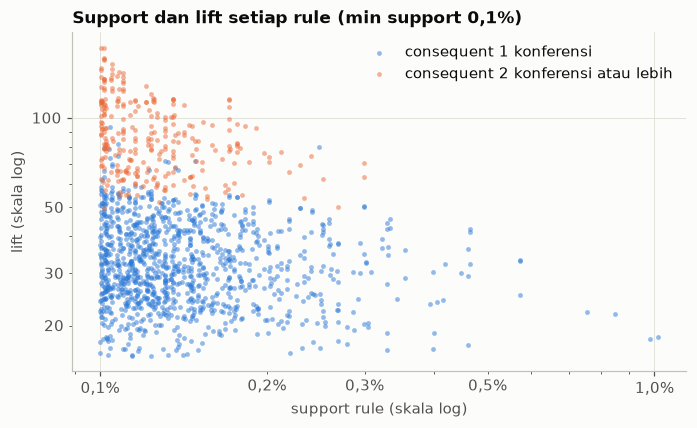

Spearman support rule vs lift: rho = -0.209 (p = 3.6e-15), 1.387 rules
Lift terendah 15.83, tertinggi 172.27; batas bawah 0,5 / support konferensi terbesar = 15.76


,rules,support_median,lift_median,lift_max
n_consequent,,,,
1,1114,0.131%,31.40,92.90
2,260,0.117%,81.42,159.38
3,13,0.101%,137.19,172.27


In [14]:
item_support_all = {next(iter(k)): c / N for k, c in itemsets[CFG.MAIN_SUPPORT].items() if len(k) == 1}
fig, ax = plt.subplots(figsize=(7.2, 4.0))
single = main["n_consequent"] == 1
ax.scatter(main.loc[single, "support"], main.loc[single, "lift"], s=10, alpha=0.5, color=CFG.BLUE, linewidths=0,
           label="consequent 1 konferensi")
ax.scatter(main.loc[~single, "support"], main.loc[~single, "lift"], s=10, alpha=0.5, color=CFG.ORANGE, linewidths=0,
           label="consequent 2 konferensi atau lebih")
ax.set_xscale("log")
ax.set_yscale("log")
pct_fmt = FuncFormatter(lambda v, _: pct_id(v * 100, 1))
num_fmt = FuncFormatter(lambda v, _: fmt_id(v))
ax.xaxis.set_major_formatter(pct_fmt)
ax.xaxis.set_minor_formatter(FuncFormatter(lambda v, _: pct_id(v * 100, 1) if round(v * 1000) in (2, 3, 5) else ""))
ax.yaxis.set_major_formatter(num_fmt)
ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: fmt_id(v) if round(v) in (20, 30, 50) else ""))
ax.set_xlabel("support rule (skala log)")
ax.set_ylabel("lift (skala log)")
ax.set_title("Support dan lift setiap rule (min support 0,1%)")
ax.legend(loc="upper right")
save_fig(fig, "t5_support_vs_lift.png")

rho, pval = spearmanr(main["support"], main["lift"])
print(f"Spearman support rule vs lift: rho = {rho:.3f} (p = {pval:.1e}), {fmt_id(len(main))} rules")
print(f"Lift terendah {main['lift'].min():.2f}, tertinggi {main['lift'].max():.2f}; batas bawah 0,5 / support konferensi terbesar = {0.5 / max(item_support_all.values()):.2f}")

by_size = main.groupby("n_consequent").agg(rules=("lift", "size"), support_median=("support", "median"),
                                           lift_median=("lift", "median"), lift_max=("lift", "max"))
save_table(by_size, "t5_lift_per_ukuran_consequent.csv")
by_size.style.format({"support_median": "{:.3%}", "lift_median": "{:.2f}", "lift_max": "{:.2f}"})

> Korelasi Spearman antara support rule dan lift adalah -0,209: rule dengan support lebih tinggi cenderung memiliki lift sedikit lebih rendah. Pola yang jauh lebih kuat ada pada ukuran consequent. Median lift rule dengan consequent satu konferensi adalah 31,40, dua konferensi 81,42, dan tiga konferensi 137,19. Lift membagi confidence dengan support consequent, dan kombinasi beberapa konferensi sekaligus selalu jarang, sehingga lift-nya membesar. Karena itu sepuluh rule dengan lift tertinggi seluruhnya memiliki consequent dua atau tiga konferensi.

## 7.2 Support Konferensi dan Lift

Pertanyaan Task 5.4 menyangkut konferensi, bukan rule. Untuk setiap konferensi yang menjadi consequent tunggal, tabel berikut membandingkan support konferensi itu dengan median dan maksimum lift rules yang mengarah kepadanya. Tabel kedua melakukan hal yang sama untuk konferensi sebagai antecedent tunggal.

In [15]:
item_support = {next(iter(s)): c / N for s, c in itemsets[CFG.MAIN_SUPPORT].items() if len(s) == 1}

def per_conference(df, side):
    rows = df[df[f"n_{side}"] == 1]
    out = (rows.assign(konferensi=rows[side].map(lambda s: names[s[0]]),
                       support_konferensi=rows[side].map(lambda s: item_support[s[0]]))
           .groupby(["konferensi", "support_konferensi"])["lift"]
           .agg(rules="size", lift_median="median", lift_max="max")
           .reset_index().sort_values("support_konferensi", ascending=False, ignore_index=True))
    rho, pval = spearmanr(out["support_konferensi"], out["lift_median"])
    return out, rho, pval

as_cons, rho_c, p_c = per_conference(main, "consequent")
as_ante, rho_a, p_a = per_conference(main, "antecedent")
save_table(as_cons, "t5_support_vs_lift_consequent.csv", index=False)
save_table(as_ante, "t5_support_vs_lift_antecedent.csv", index=False)
print(f"Konferensi sebagai consequent tunggal: {len(as_cons)}, Spearman support vs median lift: rho = {rho_c:.3f} (p = {p_c:.1e})")
print(f"Konferensi sebagai antecedent tunggal: {len(as_ante)}, Spearman support vs median lift: rho = {rho_a:.3f} (p = {p_a:.1e})")
fmt_c = {"support_konferensi": "{:.2%}", "lift_median": "{:.2f}", "lift_max": "{:.2f}"}
display(as_cons.style.format(fmt_c))
display(as_ante.style.format(fmt_c))

Konferensi sebagai consequent tunggal: 26, Spearman support vs median lift: rho = -0.933 (p = 3.8e-12)
Konferensi sebagai antecedent tunggal: 17, Spearman support vs median lift: rho = -0.517 (p = 3.4e-02)


,konferensi,support_konferensi,rules,lift_median,lift_max
0,NeurIPS,3.17%,240,23.61,29.54
1,CVPR,2.62%,160,30.21,36.70
2,AAAI,2.55%,189,25.28,34.30
3,ICASSP,2.31%,5,22.85,24.18
4,EMNLP,1.86%,54,39.52,48.78
5,ICML,1.75%,67,33.32,48.48
6,IROS,1.72%,1,29.86,29.86
7,ICLR,1.71%,91,36.31,44.58
8,CHI,1.64%,1,33.99,33.99
9,ACL,1.63%,53,43.27,53.63


,konferensi,support_konferensi,rules,lift_median,lift_max
0,ICML,1.75%,1,18.28,18.28
1,ICLR,1.71%,1,18.06,18.06
2,ICCV,1.49%,1,21.80,21.80
3,ECCV,1.29%,1,22.28,22.28
4,NAACL-HLT,0.80%,2,31.09,32.13
5,AISTATS,0.47%,2,24.86,30.44
6,BMVC,0.46%,1,20.34,20.34
7,ECOC,0.37%,1,80.12,80.12
8,Conference on Designing Interactive Systems,0.31%,1,33.99,33.99
9,EACL,0.27%,2,34.72,36.59


> Jawaban Task 5.4: tidak. Konferensi dengan support tinggi justru menghasilkan lift yang rendah. Di antara 26 konferensi yang menjadi consequent tunggal, korelasi Spearman antara support konferensi dan median lift rules yang menuju kepadanya adalah -0,933. NeurIPS, konferensi dengan support tertinggi (3,17%), menjadi consequent pada 240 rule, terbanyak dari semua konferensi, tetapi median lift-nya hanya 23,61, kedua terendah setelah ICASSP (22,85). Sebaliknya CDC (support 0,79%) memiliki median lift 92,90. Sebagai antecedent tunggal, korelasinya -0,517 pada 17 konferensi.
>
> Penyebabnya ada pada rumus lift = confidence / support(Y). Konferensi besar sudah memiliki support tinggi, sehingga rule yang menuju kepadanya sulit mencapai lift tinggi walaupun confidence-nya besar. Jadi konferensi terpopuler memiliki paling banyak asosiasi, tetapi bukan asosiasi yang paling kuat.

---

# Interpretasi Support, Confidence, dan Lift (Task 5.5) <a name="8"></a>

---

Tiga rule nyata dipakai sebagai contoh: rule satu-satunya pada min support 1% (ICML → NeurIPS), rule satu-ke-satu dengan lift tertinggi, dan rule dengan lift tertinggi secara keseluruhan. Untuk setiap rule ditampilkan count di balik ketiga metrik.

In [16]:
ids = {v: k for k, v in names.items()}
icml_neurips = main[is_tuple(main["antecedent"], (ids["ICML"],)) & is_tuple(main["consequent"], (ids["NeurIPS"],))]
examples = pd.concat([icml_neurips, one.head(1), main.head(1)], ignore_index=True)
examples["support_Y"] = examples["consequent_count"] / N
ex_cols = ["rule", "count", "antecedent_count", "consequent_count", "support", "confidence", "support_Y", "lift"]
save_table(examples[ex_cols], "t5_contoh_metrik.csv", index=False)
examples[ex_cols].style.format({"support": "{:.3%}", "confidence": "{:.1%}", "support_Y": "{:.3%}", "lift": "{:.2f}"})

,rule,count,antecedent_count,consequent_count,support,confidence,support_Y,lift
0,ICML → NeurIPS,18503,31896,57800,1.016%,58.0%,3.173%,18.28
1,ECOC → OFC,4530,6815,15115,0.249%,66.5%,0.830%,80.12
2,ECCV + ACM Multimedia + NeurIPS → AAAI + CVPR + ICCV,1827,2983,6477,0.100%,61.2%,0.356%,172.27


Rule ICML → NeurIPS berarti 18.503 author pernah publish di ICML dan juga di NeurIPS. Ketiga metriknya dibaca sebagai berikut.

- **Support 1,016%** (18.503 / 1.821.757): seberapa umum kombinasi ICML dan NeurIPS di antara seluruh author. Support tidak memiliki arah; NeurIPS → ICML memiliki support yang sama.
- **Confidence 58,0%** (18.503 / 31.896 author ICML): dari author ICML, 58% juga publish di NeurIPS. Confidence memiliki arah; NeurIPS → ICML hanya 32,0% (18.503 / 57.800), di bawah ambang 50%, sehingga tidak menjadi rule.
- **Lift 18,28** (58,0% / 3,17%): author ICML 18 kali lebih mungkin publish di NeurIPS dibanding author pada umumnya. Lift tidak memiliki arah; nilainya sama untuk NeurIPS → ICML.

Ketiga contoh memperlihatkan bahwa ketiga metrik menjawab pertanyaan berbeda. ICML → NeurIPS memiliki support terbesar tetapi lift terkecil. ECOC → OFC hanya didukung 0,249% author tetapi lift-nya 80,12. Rule panjang dengan lift 172,27 hanya didukung 0,100% author, tepat di atas ambang. Support menjawab *seberapa sering*, confidence menjawab *seberapa sering B jika A*, dan lift menjawab *seberapa kuat hubungan A dan B dibanding jika keduanya tidak berkaitan*.

Pada data ini lift tidak berfungsi sebagai penyaring. Setiap konferensi memiliki support di bawah 3,2%, dan min confidence 50%, sehingga setiap rule otomatis memiliki lift minimal sekitar 15,8 (lift terendah pada bagian 7.1 adalah 15,83). Lift dipakai untuk mengurutkan kekuatan hubungan, bukan untuk memisahkan hubungan positif dan negatif.

---

# Pola Publikasi Antarkonferensi (Task 5.6) <a name="9"></a>

---

## 9.1 Kelompok Konferensi dari Rules Satu-ke-Satu

Setiap rule satu-ke-satu dianggap sebagai garis yang menghubungkan dua konferensi. Konferensi yang terhubung, langsung maupun lewat konferensi lain, membentuk satu kelompok. Kelompok ini menunjukkan konferensi-konferensi yang author-nya saling bertumpang tindih kuat (confidence minimal 50%).

In [17]:
parent = {}

def find(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

for a, c in zip(one["antecedent"], one["consequent"]):
    parent[find(a[0])] = find(c[0])

groups = {}
for item in list(parent):
    groups.setdefault(find(item), []).append(item)

def group_row(members):
    inside = one[one["antecedent"].map(lambda s: s[0] in members)]
    return {"anggota": ", ".join(sorted(names[i] for i in members)), "jumlah_konferensi": len(members),
            "rules": len(inside), "rule_lift_tertinggi": inside.iloc[0]["rule"], "lift_tertinggi": inside.iloc[0]["lift"]}

comp = pd.DataFrame([group_row(m) for m in groups.values()]).sort_values(
    ["jumlah_konferensi", "lift_tertinggi"], ascending=[False, False], ignore_index=True)
save_table(comp, "t5_kelompok_konferensi.csv", index=False)
comp.style.format({"lift_tertinggi": "{:.2f}"})

,anggota,jumlah_konferensi,rules,rule_lift_tertinggi,lift_tertinggi
0,"3DV, ACCV, BMVC, CVPR, ECCV, ICCV",6,5,3DV → CVPR,25.02
1,"ACL, EACL, EMNLP, IJCNLP-AACL, NAACL-HLT",5,6,EACL → ACL,36.59
2,"AISTATS, ICLR, ICML, NeurIPS, UAI",5,5,AISTATS → ICML,30.44
3,"GLOBECOM, ICC, SPAWC",3,2,SPAWC → ICC,36.23
4,"ECOC, OFC",2,1,ECOC → OFC,80.12
5,"ASRU, INTERSPEECH",2,1,ASRU → INTERSPEECH,74.17
6,"CoRL, ICRA",2,1,CoRL → ICRA,37.11
7,"CHI, Conference on Designing Interactive Systems",2,1,Conference on Designing Interactive Systems → CHI,33.99


> Rules satu-ke-satu membentuk delapan kelompok yang terpisah, dan setiap kelompok adalah satu bidang riset: computer vision (CVPR, ICCV, ECCV, BMVC, ACCV, 3DV), NLP (ACL, EMNLP, NAACL-HLT, EACL, IJCNLP-AACL), machine learning (NeurIPS, ICML, ICLR, AISTATS, UAI), komunikasi nirkabel (ICC, GLOBECOM, SPAWC), komunikasi optik (OFC, ECOC), pengenalan suara (INTERSPEECH, ASRU), robotika (ICRA, CoRL), dan interaksi manusia-komputer (CHI, Conference on Designing Interactive Systems). Tidak ada rule satu-ke-satu yang menghubungkan dua kelompok.
>
> Setiap kelompok memiliki konferensi utama yang menjadi tujuan rules dari konferensi yang lebih kecil: CVPR menerima lima rule, NeurIPS empat, serta ACL dan EMNLP masing-masing tiga.

## 9.2 Konferensi yang Paling Sering Menjadi Consequent

Rules dengan consequent satu konferensi menunjukkan ke mana author dari kombinasi konferensi lain "mengarah". Tabel berikut menghitung, untuk setiap konferensi, berapa rule yang berakhir padanya.

In [18]:
cons_single = main[main["n_consequent"] == 1]
target = (cons_single["consequent"].map(lambda s: names[s[0]]).value_counts()
          .rename_axis("konferensi").reset_index(name="rules_menuju"))
target["persen_dari_rules"] = target["rules_menuju"] / len(cons_single) * 100
save_table(target, "t5_consequent_terbanyak.csv", index=False)
print(f"Rules dengan consequent satu konferensi: {fmt_id(len(cons_single))}")
target.head(CFG.TOP_K).style.format({"persen_dari_rules": "{:.1f}"})

Rules dengan consequent satu konferensi: 1.114


,konferensi,rules_menuju,persen_dari_rules
0,NeurIPS,240,21.5
1,AAAI,189,17.0
2,CVPR,160,14.4
3,ICCV,101,9.1
4,ICLR,91,8.2
5,ECCV,70,6.3
6,ICML,67,6.0
7,EMNLP,54,4.8
8,ACL,53,4.8
9,ACM Multimedia,22,2.0


> Dari 1.114 rule dengan consequent satu konferensi, 21,5% menuju NeurIPS, 17,0% menuju AAAI, dan 14,4% menuju CVPR. AAAI menarik: tidak ada rule satu-ke-satu yang menuju AAAI, tetapi 189 rule menuju AAAI dari kombinasi dua konferensi atau lebih. Artinya, publish di satu konferensi tertentu belum cukup untuk memperkirakan author juga publish di AAAI, tetapi author yang publish di beberapa konferensi machine learning dan computer vision sekaligus sangat mungkin juga publish di AAAI.

---

# Interpretasi dan Keterbatasan <a name="10"></a>

---

**Pola publikasi antarkonferensi (Task 5.6).**

1. *Hubungan kuat hanya terjadi di dalam satu bidang.* Seluruh 22 rule satu-ke-satu berada di dalam salah satu dari delapan bidang, dan tidak ada yang menghubungkan dua bidang.
2. *Arahnya dari konferensi yang lebih kecil ke konferensi utama.* Mayoritas author EACL, BMVC, AISTATS, CoRL, dan konferensi lain yang lebih kecil juga publish di konferensi utama bidangnya, tetapi tidak sebaliknya. Tidak ada satu pun pasangan yang berlaku dua arah.
3. *Konferensi utama yang ukurannya mirip paling mendekati timbal balik.* CVPR dengan ICCV dan ECCV, serta NeurIPS dengan ICML dan ICLR, memiliki confidence arah balik sekitar 29% sampai 32%, tertinggi di antara seluruh pasangan.
4. *Kombinasi beberapa konferensi mengarah ke NeurIPS, AAAI, dan CVPR.* Author yang publish di beberapa konferensi machine learning dan computer vision sekaligus sangat mungkin juga publish di ketiga konferensi tersebut.

**Apakah konferensi terpopuler juga memiliki asosiasi terkuat?** Tidak. NeurIPS menjadi consequent pada rules terbanyak (240), tetapi median lift-nya termasuk yang terendah (23,61). Asosiasi terkuat justru ada pada pasangan konferensi di bidang yang sempit, seperti ECOC → OFC (lift 80,12) dan ASRU → INTERSPEECH (74,17).

**Rule dengan lift tertinggi.** ECCV + ACM Multimedia + NeurIPS → AAAI + CVPR + ICCV (lift 172,27). Dari 2.983 author yang publish di ECCV, ACM Multimedia, dan NeurIPS, 61,2% juga publish di AAAI, CVPR, dan ICCV, atau 172 kali lebih sering dibanding author pada umumnya. Rule ini hanya berlaku untuk 1.827 author. Rule satu-ke-satu dengan lift tertinggi adalah ECOC → OFC (lift 80,12).

**Keterbatasan.**

1. Seluruh keterbatasan Task 4 tetap berlaku: item adalah key DBLP (workshop dapat terpisah dari konferensi utamanya), identitas author mengikuti disambiguasi DBLP, support menghitung author bukan paper, dan author-based menggabungkan seluruh 2015-2025.
2. Rules hanya ada untuk kombinasi yang lolos min support 0,1%. Hubungan kuat antara dua konferensi kecil tidak terlihat.
3. Dengan min confidence 50% dan support setiap konferensi di bawah 3,2%, lift setiap rule minimal sekitar 15,8. Nilai lift yang tinggi pada data ini sebagian besar mencerminkan kecilnya support konferensi, sehingga lift lebih tepat dipakai untuk membandingkan rules daripada sebagai ukuran mutlak.
4. Sepuluh rule dengan lift tertinggi berada tepat di atas ambang (count 1.827 sampai 1.973 terhadap ambang 1.822), sehingga sensitif terhadap perubahan kecil pada data, misalnya profil author gabungan di DBLP.

---

# Ringkasan dan Langkah Berikutnya <a name="11"></a>

---

| Task | Hasil | Bagian |
|---|---|---|
| 5.1 | 1.387 rules pada 0,1%, 7 pada 0,5%, 1 pada 1%, 0 pada 2%; identik dengan `mlxtend` | 4 |
| 5.2 | Support, confidence, dan lift setiap rule; sepuluh lift tertinggi dipimpin ECCV + ACM Multimedia + NeurIPS → AAAI + CVPR + ICCV (172,27) | 5 |
| 5.3 | Tidak ada pasangan dua arah; hubungan terkuat ECOC → OFC (80,12) dan ASRU → INTERSPEECH (74,17); pasangan paling timbal balik CVPR dengan ICCV/ECCV dan NeurIPS dengan ICML/ICLR | 6 |
| 5.4 | Support tinggi tidak berarti lift tinggi; Spearman support konferensi vs median lift -0,933; NeurIPS paling banyak rules tetapi median lift 23,61 | 7 |
| 5.5 | Support = seberapa sering, confidence = seberapa sering B jika A (berarah), lift = kekuatan dibanding independen (tidak berarah) | 8 |
| 5.6 | Delapan kelompok bidang tanpa hubungan antarkelompok; arah dari konferensi kecil ke konferensi utama | 9, 10 |

Rules setiap min support disimpan di `outputs/rules/rules_<tag>.parquet`. Notebook `06_performance` memakai jumlah rules ini untuk membandingkan Apriori dan FP-Growth, dan notebook `07_temporal` memakai `src/rules.py` untuk setiap periode.